# Day 7 — Random Forest challenger for 60-day player churn

Day 6's **unweighted Logistic Regression remains the official baseline**. Random Forest is a challenger that can learn nonlinear splits and interactions without specifying them beforehand. Logistic Regression estimates an additive relationship in log odds; an ensemble of bootstrap-trained trees averages more flexible predictions. We compare model families on the approved validation period; XGBoost remains to be tested before any final winner is declared.

The outcome represents extended betting inactivity, not guaranteed permanent departure. No resampling, probability calibration or production threshold selection is performed here. **The test period remains sealed.**

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, time
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'features.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'features.py').exists()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import joblib, sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from src.features import TARGET_COLUMN, PREDICTOR_COLUMNS
from src.preprocessing import (validate_model_panel, temporal_split_labels, predictor_frame,
                               build_random_forest_pipeline, NUMERIC_COLUMNS)
from src.evaluation import classification_metrics, ranking_metrics, cumulative_gains_table, threshold_analysis
from src.random_forest import RF_CANDIDATES, modelling_partition, guarded_probabilities, evaluate_candidate, select_candidate
REPORTS = ROOT / 'reports'
FIGURES = REPORTS / 'figures'
MODELS = ROOT / 'models'
for directory in [REPORTS, FIGURES, MODELS]:
    directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / ('random_forest_' + name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## Approved temporal split and sealed test

TRAIN: 2005-03-31–2005-12-31. January–February 2006 embargo.
VALIDATION: 2006-03-31–2006-05-31. June–July 2006 embargo.
TEST: 2006-08-31–2006-11-30.

The model only receives training and validation predictors. Test is summarized by row count, snapshot dates and target prevalence only. Metadata (`UserID`, `snapshot_date`) and target are excluded by the shared predictor selector and ColumnTransformer. Validation supports model comparison; the untouched test will later assess the selected model family's generalization.

In [2]:
data_path = ROOT / 'data' / 'processed' / 'model_panel_60d.csv'
panel = pd.read_csv(data_path, parse_dates=['snapshot_date'])
validate_model_panel(panel)
labels = temporal_split_labels(panel.snapshot_date)
split_summary = pd.DataFrame([
    {'split': split, 'row_count': int(labels.eq(split).sum()),
     'snapshot_dates': ', '.join(panel.loc[labels.eq(split), 'snapshot_date'].dt.strftime('%Y-%m-%d').sort_values().unique()),
     'churn_prevalence': panel.loc[labels.eq(split), TARGET_COLUMN].mean()}
    for split in ['train', 'embargo', 'validation', 'test']])
display(split_summary)
train = modelling_partition(panel, 'train')
validation = modelling_partition(panel, 'validation')
del panel, labels  # No test predictor frame is constructed or retained.
X_train, y_train = predictor_frame(train), train[TARGET_COLUMN]
X_validation, y_validation = predictor_frame(validation), validation[TARGET_COLUMN]
assert not {'UserID', 'snapshot_date', TARGET_COLUMN}.intersection(X_train.columns)
assert train.snapshot_date.max() == pd.Timestamp('2005-12-31')
assert validation.snapshot_date.min() == pd.Timestamp('2006-03-31')
split_summary.to_csv(REPORTS / 'random_forest_split_summary.csv', index=False)

,split,row_count,snapshot_dates,churn_prevalence
0,train,10380,"2005-03-31, 2005-04-30, 2005-05-31, 2005-06-30...",0.360886
1,embargo,3070,"2006-01-31, 2006-02-28, 2006-06-30, 2006-07-31",0.365147
2,validation,2184,"2006-03-31, 2006-04-30, 2006-05-31",0.353938
3,test,2838,"2006-08-31, 2006-09-30, 2006-10-31, 2006-11-30",0.340733


## Train-fitted preprocessing and initial forest

Numeric predictors use median imputation with missingness indicators. Country, Language and Gender use most-frequent imputation and one-hot encoding with unknown categories ignored. All preprocessing is fitted on TRAIN within a sklearn Pipeline. Tree splits use ordering/cut points, so numerical standardization is unnecessary. Undefined ratios remain missing until train-fitted imputation.

The initial unweighted forest uses 500 trees, unrestricted depth, leaf size 1, `max_features="sqrt"`, seed 42 and all available cores. Its training versus validation gap diagnoses overfitting; training metrics are resubstitution metrics, not an independent estimate.

In [3]:
pipelines, records = {}, []
initial_config = RF_CANDIDATES[0]
initial = build_random_forest_pipeline(**{k: v for k, v in initial_config.items() if k != 'name'})
start = time.perf_counter()
initial_metrics = evaluate_candidate(initial, train, validation)
pipelines['initial'] = initial
records.append({**initial_config, 'n_estimators': 500, 'class_weight': 'unweighted',
                **initial_metrics, 'fit_evaluate_seconds': time.perf_counter() - start})
display(pd.Series(initial_metrics, name='initial_forest').to_frame())
pre = initial['preprocessing']
transformed = pre.transform(X_validation)
values = transformed.toarray() if hasattr(transformed, 'toarray') else transformed
assert values.shape[0] == len(validation) and np.isfinite(values).all()
np.testing.assert_allclose(pre.named_transformers_['numeric']['imputer'].statistics_, X_train[NUMERIC_COLUMNS].median())
del transformed, values

,initial_forest
roc_auc,0.712787
average_precision,0.515427
log_loss,0.572531
brier_score,0.198575
accuracy,0.655678
balanced_accuracy,0.580852
precision,0.521830
recall,0.324709
f1,0.400319
specificity,0.836995


## Compact overfitting investigation and predeclared selection

Seven primary configurations cover depth None/8/12/16, leaf size 1/5/10/20 and features sqrt/0.5 without a Cartesian search. Unlimited depth with larger leaves isolates leaf regularization; constrained forests examine depth and feature sampling. Smaller leaves and unrestricted trees can memorize sparse, repeated observations. Depth limits and larger leaves reduce that flexibility. Each candidate uses 500 trees, seed 42, `n_jobs=-1` and no class weights.

**Selection rule declared before results:** retain candidates within 0.002 of the highest validation average precision, then within 0.002 ROC-AUC, then within 0.02 Lift@10%, then within 0.002 Recall@10%. Among those ranking ties, retain candidates within 0.02 of the smallest train–validation AP gap, then within 0.002 of the lowest Brier score. Finally prefer shallower depth and larger leaves, breaking remaining ties by AP and name. Differences are absolute, not relative. These pragmatic near-tie tolerances are not statistical significance tests; they prefer simpler, better-generalizing candidates when ranking is essentially tied. Accuracy is not a selection criterion.

ROC-AUC and AP gaps are reported for every candidate. The AP gap drives the tie-break because AP is the primary ranking objective.

In [4]:
display(pd.DataFrame(RF_CANDIDATES))
for config in RF_CANDIDATES[1:]:
    start = time.perf_counter()
    pipe = build_random_forest_pipeline(**{k: v for k, v in config.items() if k != 'name'})
    metrics = evaluate_candidate(pipe, train, validation)
    pipelines[config['name']] = pipe
    records.append({**config, 'n_estimators': 500, 'class_weight': 'unweighted',
                    **metrics, 'fit_evaluate_seconds': time.perf_counter() - start})
    print(config['name'], 'validation AP:', round(metrics['average_precision'], 4),
          'AP gap:', round(metrics['average_precision_gap'], 4), flush=True)
candidates = pd.DataFrame(records)
selected_name = select_candidate(candidates)
selected = pipelines[selected_name]
selected_record = candidates.set_index('name').loc[selected_name]
candidates.to_csv(REPORTS / 'random_forest_candidates.csv', index=False)
display(candidates[['name', 'max_depth', 'min_samples_leaf', 'max_features', 'train_roc_auc',
                    'roc_auc', 'roc_auc_gap', 'train_average_precision', 'average_precision',
                    'average_precision_gap', 'lift_at_top10pct', 'recall_at_top10pct', 'brier_score']])
print('Selected primary configuration:', selected_name)
del pipelines, initial, pipe  # retain only the selected forest

,name,max_depth,min_samples_leaf,max_features
0,initial,NaN,1,sqrt
1,unlimited_leaf20,NaN,20,sqrt
2,depth8_leaf5,8.0,5,sqrt
3,depth12_leaf10,12.0,10,sqrt
4,depth16_leaf20,16.0,20,sqrt
5,depth12_leaf10_half,12.0,10,0.5
6,depth8_leaf20_half,8.0,20,0.5


unlimited_leaf20 validation AP: 0.5562 AP gap: 0.1819


depth8_leaf5 validation AP: 0.5554 AP gap: 0.1141


depth12_leaf10 validation AP: 0.5496 AP gap: 0.2137


depth16_leaf20 validation AP: 0.5566 AP gap: 0.1727


depth12_leaf10_half validation AP: 0.5402 AP gap: 0.311


depth8_leaf20_half validation AP: 0.5594 AP gap: 0.1265


,name,max_depth,min_samples_leaf,max_features,train_roc_auc,roc_auc,roc_auc_gap,train_average_precision,average_precision,average_precision_gap,lift_at_top10pct,recall_at_top10pct,brier_score
0,initial,NaN,1,sqrt,1.000000,0.712787,0.287213,1.000000,0.515427,0.484573,1.535239,0.153946,0.198575
1,unlimited_leaf20,NaN,20,sqrt,0.836859,0.739829,0.097030,0.738047,0.556182,0.181865,1.690053,0.169470,0.191539
2,depth8_leaf5,8.0,5,sqrt,0.811809,0.740614,0.071195,0.669484,0.555388,0.114096,1.715855,0.172057,0.191842
3,depth12_leaf10,12.0,10,sqrt,0.860647,0.738021,0.122626,0.763241,0.549588,0.213654,1.702954,0.170763,0.192113
4,depth16_leaf20,16.0,20,sqrt,0.833760,0.739948,0.093812,0.729334,0.556591,0.172743,1.702954,0.170763,0.191502
5,depth12_leaf10_half,12.0,10,0.5,0.908138,0.729564,0.178573,0.851270,0.540247,0.311023,1.677152,0.168176,0.193868
6,depth8_leaf20_half,8.0,20,0.5,0.817764,0.741491,0.076273,0.685894,0.559362,0.126532,1.767460,0.177232,0.191108


Selected primary configuration: depth8_leaf20_half


## Class weight sensitivity

Prevalence near 36% does not imply severe class imbalance. The primary forest stays unweighted. We fit one `balanced_subsample` sensitivity using the selected structure; it cannot enter primary selection. Compare ranking, precision/recall and probability quality empirically rather than assuming weights help.

In [5]:
selected_params = selected['model'].get_params()
structural_params = {k: selected_params[k] for k in ['n_estimators', 'max_depth', 'min_samples_leaf', 'max_features']}
weighted = build_random_forest_pipeline(**structural_params, class_weight='balanced_subsample')
weighted_metrics = evaluate_candidate(weighted, train, validation)
probability = guarded_probabilities(selected, validation, 'validation')
train_probability = guarded_probabilities(selected, train, 'train')
weighted_probability = guarded_probabilities(weighted, validation, 'validation')
sensitivity = pd.DataFrame([
    {'model': 'selected_unweighted', **classification_metrics(y_validation, probability),
     **ranking_metrics(y_validation, probability), 'mean_predicted_probability': probability.mean()},
    {'model': 'balanced_subsample_sensitivity', **weighted_metrics,
     'mean_predicted_probability': weighted_probability.mean()}])
sensitivity['observed_churn_prevalence'] = y_validation.mean()
sensitivity.to_csv(REPORTS / 'random_forest_weight_sensitivity.csv', index=False)
display(sensitivity[['model', 'roc_auc', 'average_precision', 'precision', 'recall',
                     'lift_at_top10pct', 'brier_score', 'mean_predicted_probability', 'observed_churn_prevalence']])
del weighted, weighted_probability

,model,roc_auc,average_precision,precision,recall,lift_at_top10pct,brier_score,mean_predicted_probability,observed_churn_prevalence
0,selected_unweighted,0.741491,0.559362,0.614118,0.337646,1.767460,0.191108,0.344761,0.353938
1,balanced_subsample_sensitivity,0.741391,0.555919,0.505667,0.750323,1.715855,0.197314,0.435348,0.353938


## Selected model: validation metrics and diagnostic confusion matrix

AP is sklearn's Average Precision, used consistently as the PR-AUC summary in Day 6. Threshold 0.50 is diagnostic only; it does not set the production retention policy.

,selected_random_forest
model,random_forest_unweighted
selected_candidate,depth8_leaf20_half
split,validation
threshold,0.5
roc_auc,0.741491
average_precision,0.559362
log_loss,0.553515
brier_score,0.191108
accuracy,0.690476
balanced_accuracy,0.610708


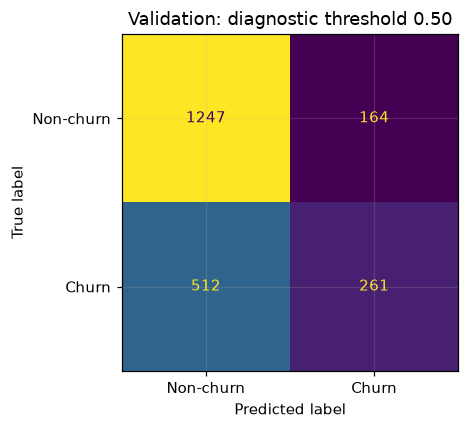

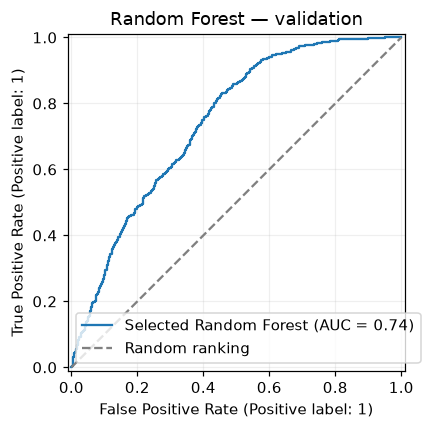

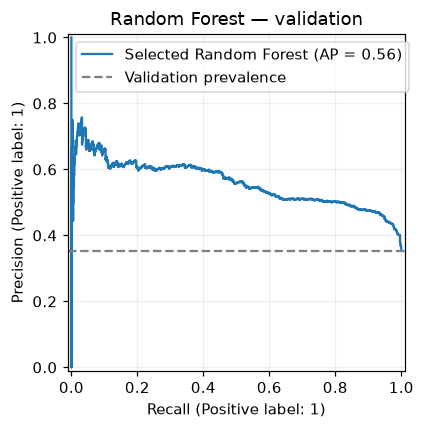

In [6]:
validation_metrics = {**classification_metrics(y_validation, probability), **ranking_metrics(y_validation, probability)}
training_metrics = classification_metrics(y_train, train_probability)
metric_row = {'model': 'random_forest_unweighted', 'selected_candidate': selected_name,
              'split': 'validation', 'threshold': .5, **validation_metrics,
              'train_roc_auc': training_metrics['roc_auc'], 'train_average_precision': training_metrics['average_precision'],
              'roc_auc_gap': training_metrics['roc_auc'] - validation_metrics['roc_auc'],
              'average_precision_gap': training_metrics['average_precision'] - validation_metrics['average_precision'],
              'mean_predicted_probability': probability.mean(), 'observed_churn_prevalence': y_validation.mean()}
pd.DataFrame([metric_row]).to_csv(REPORTS / 'random_forest_validation_metrics.csv', index=False)
display(pd.Series(metric_row, name='selected_random_forest').to_frame())
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_validation, probability >= .5, display_labels=['Non-churn', 'Churn'], ax=ax, colorbar=False)
ax.set_title('Validation: diagnostic threshold 0.50')
save_figure(fig, 'confusion_matrix')
for display_class, name in [(RocCurveDisplay, 'roc'), (PrecisionRecallDisplay, 'precision_recall')]:
    fig, ax = plt.subplots(figsize=(6, 4))
    display_class.from_predictions(y_validation, probability, ax=ax, name='Selected Random Forest')
    if name == 'roc':
        ax.plot([0, 1], [0, 1], '--', color='gray', label='Random ranking')
    else:
        ax.axhline(y_validation.mean(), linestyle='--', color='gray', label='Validation prevalence')
    ax.set_title('Random Forest — validation')
    ax.legend()
    save_figure(fig, name)

## Ranking, gains and Logistic Regression comparison

Use Day 6's exact shared definitions: select `ceil(n × fraction)` player-snapshot rows, descending probability with stable input-order ties. Precision is selected-group prevalence, recall is captured churn observations divided by all validation churn observations, and lift is precision divided by validation prevalence. These are observations, not deduplicated campaign recipients. No labels break score ties.

Differences below are Random Forest minus the tracked **unweighted** Logistic Regression baseline. Lower Brier is better; higher ranking and precision/recall/F1 values are better. A heuristic +0.01 AP and +0.01 ROC-AUC indicates a practically material ranking gain here, not a statistical test. Top-budget metrics also need inspection.

,target_fraction,selected_observations,actual_fraction,churn_observations_captured,precision,recall,lift
0,0.1,219,0.100275,137,0.625571,0.177232,1.767460
1,0.2,437,0.200092,266,0.608696,0.344114,1.719782
2,0.3,656,0.300366,374,0.570122,0.483829,1.610797
3,0.4,874,0.400183,462,0.528604,0.597671,1.493495
4,0.5,1092,0.500000,557,0.510073,0.720569,1.441138
5,0.6,1311,0.600275,646,0.492754,0.835705,1.392204
6,0.7,1529,0.700092,717,0.468934,0.927555,1.324905
7,0.8,1748,0.800366,754,0.431350,0.975420,1.218718
8,0.9,1966,0.900183,770,0.391658,0.996119,1.106574
9,1.0,2184,1.000000,773,0.353938,1.000000,1.000000


,Metric,Logistic Regression,Random Forest,Difference
0,roc_auc,0.729547,0.741491,0.011944
1,average_precision,0.534197,0.559362,0.025165
2,brier_score,0.196285,0.191108,-0.005177
3,precision,0.547425,0.614118,0.066692
4,recall,0.261320,0.337646,0.076326
5,f1,0.353765,0.435726,0.081961
6,lift_at_top10pct,1.586844,1.767460,0.180616
7,recall_at_top10pct,0.159120,0.177232,0.018111
8,lift_at_top20pct,1.577544,1.719782,0.142238
9,recall_at_top20pct,0.315653,0.344114,0.028461


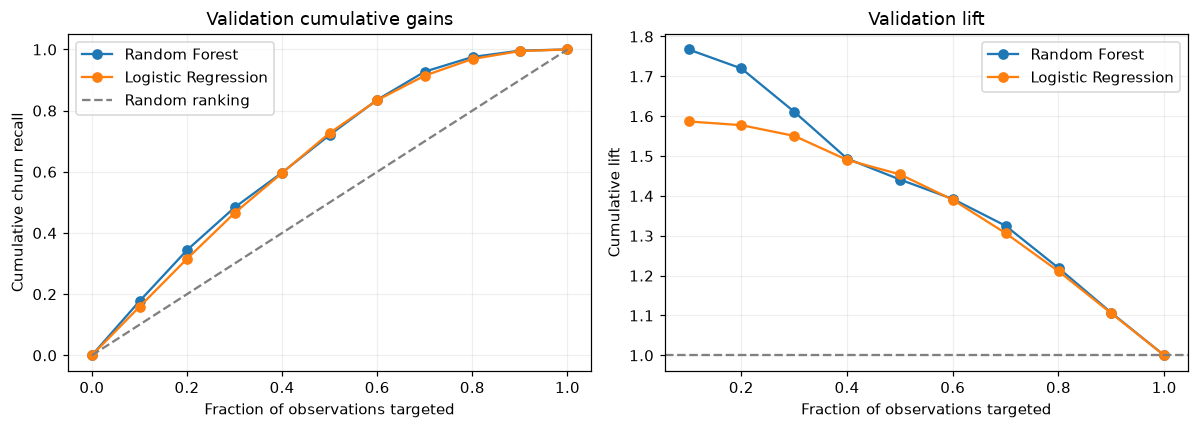

Random Forest materially improves validation ranking: AP change **+0.0252**, ROC-AUC change **+0.0119**. Top-10% lift change **+0.1806**. This is a descriptive comparison on one validation window, not proof of statistical significance. **No final winner is declared; XGBoost remains pending.**

In [7]:
gains = cumulative_gains_table(y_validation, probability)
gains.to_csv(REPORTS / 'random_forest_validation_cumulative_gains.csv', index=False)
display(gains)
baseline_path = REPORTS / 'logistic_baseline_validation_metrics.csv'
baseline = pd.read_csv(baseline_path).query("model == 'logistic_unweighted' and split == 'validation'")
assert len(baseline) == 1
baseline = baseline.iloc[0]
comparison_keys = ['roc_auc', 'average_precision', 'brier_score', 'precision', 'recall', 'f1',
                   'lift_at_top10pct', 'recall_at_top10pct', 'lift_at_top20pct', 'recall_at_top20pct']
comparison = pd.DataFrame({'Metric': comparison_keys,
                          'Logistic Regression': [baseline[k] for k in comparison_keys],
                          'Random Forest': [validation_metrics[k] for k in comparison_keys]})
comparison['Difference'] = comparison['Random Forest'] - comparison['Logistic Regression']
comparison.to_csv(REPORTS / 'model_validation_comparison.csv', index=False)
display(comparison)
baseline_gains = pd.read_csv(REPORTS / 'logistic_baseline_validation_cumulative_gains.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for table, label in [(gains, 'Random Forest'), (baseline_gains, 'Logistic Regression')]:
    axes[0].plot(np.r_[0, table.actual_fraction], np.r_[0, table.recall], marker='o', label=label)
    axes[1].plot(table.actual_fraction, table.lift, marker='o', label=label)
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Random ranking')
axes[0].set(xlabel='Fraction of observations targeted', ylabel='Cumulative churn recall', title='Validation cumulative gains')
axes[1].axhline(1, linestyle='--', color='gray')
axes[1].set(xlabel='Fraction of observations targeted', ylabel='Cumulative lift', title='Validation lift')
for ax in axes: ax.legend()
save_figure(fig, 'gains_lift')
ap_delta = validation_metrics['average_precision'] - baseline['average_precision']
roc_delta = validation_metrics['roc_auc'] - baseline['roc_auc']
material = ap_delta >= .01 and roc_delta >= .01
display(Markdown(f"Random Forest {'materially improves' if material else 'does not meet the declared material-improvement criterion for'} validation ranking: AP change **{ap_delta:+.4f}**, ROC-AUC change **{roc_delta:+.4f}**. Top-10% lift change **{validation_metrics['lift_at_top10pct'] - baseline['lift_at_top10pct']:+.4f}**. This is a descriptive comparison on one validation window, not proof of statistical significance. **No final winner is declared; XGBoost remains pending.**"))

## Threshold diagnostics and probability calibration

All thresholds use validation only. We neither optimize the business threshold nor calibrate probabilities. Reliability bins compare mean raw predicted probability with observed churn frequency; bins with few rows are noisy. Brier summarizes squared probability error. Mean probability below prevalence indicates average underprediction of risk, not by itself confidence miscalibration. Underconfidence means probabilities are too close to the base rate; overconfidence means they are too extreme. Judge those patterns using the reliability curve, not merely the marginal mean.

,threshold,precision,recall,f1,specificity,predicted_positives
0,0.2,0.456184,0.949547,0.616289,0.379872,1609
1,0.3,0.478693,0.871928,0.618065,0.479802,1408
2,0.4,0.510502,0.723157,0.598501,0.620128,1095
3,0.5,0.614118,0.337646,0.435726,0.883770,425
4,0.6,0.723404,0.043984,0.082927,0.990787,47
5,0.7,0.000000,0.000000,0.000000,1.000000,0
6,0.8,0.000000,0.000000,0.000000,1.000000,0


,mean_predicted_probability,observed_churn_rate,observations
0,0.044765,0.013699,219
1,0.099257,0.073394,218
2,0.185406,0.169725,218
3,0.294114,0.324201,219
4,0.375099,0.408257,218
5,0.419877,0.435780,218
6,0.451049,0.406393,219
7,0.482047,0.490826,218
8,0.517899,0.591743,218
9,0.578151,0.625571,219


Brier: 0.1911079068218055 mean probability: 0.3447614274218784 observed churn: 0.35393772893772896


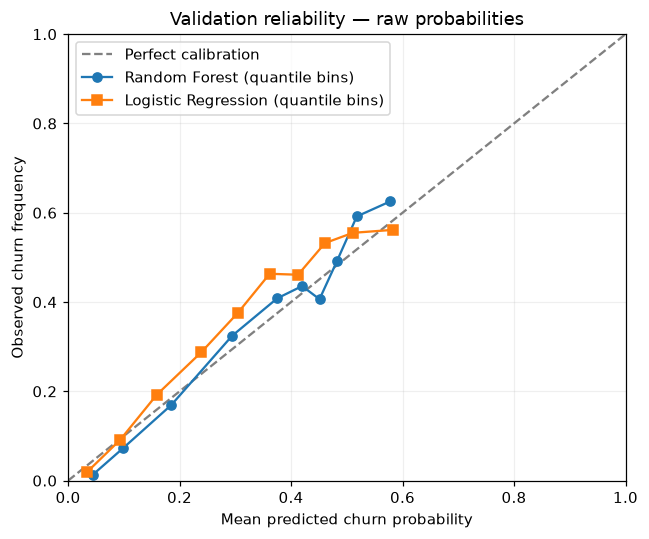

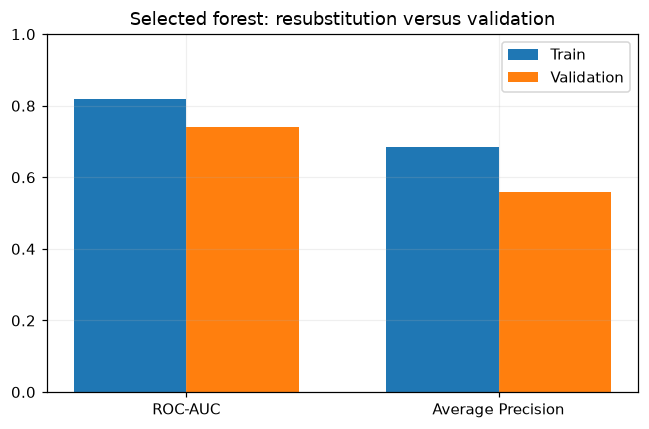

In [8]:
thresholds = threshold_analysis(y_validation, probability)
thresholds.to_csv(REPORTS / 'random_forest_validation_thresholds.csv', index=False)
display(thresholds)
observed_bins, predicted_bins = calibration_curve(y_validation, probability, n_bins=10, strategy='quantile')
calibration = pd.DataFrame({'mean_predicted_probability': predicted_bins, 'observed_churn_rate': observed_bins})
bin_ids = np.searchsorted(np.percentile(probability, np.linspace(0, 100, 11))[1:-1], probability)
calibration['observations'] = np.bincount(bin_ids, minlength=10)
assert calibration.observations.sum() == len(validation)
calibration.to_csv(REPORTS / 'random_forest_validation_calibration.csv', index=False)
display(calibration)
print('Brier:', validation_metrics['brier_score'], 'mean probability:', probability.mean(), 'observed churn:', y_validation.mean())
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
ax.plot(predicted_bins, observed_bins, marker='o', label='Random Forest (quantile bins)')
baseline_calibration = pd.read_csv(REPORTS / 'logistic_baseline_validation_calibration.csv')
ax.plot(baseline_calibration.mean_probability, baseline_calibration.observed_churn_rate,
        marker='s', label='Logistic Regression (quantile bins)')
ax.set(xlabel='Mean predicted churn probability', ylabel='Observed churn frequency', title='Validation reliability — raw probabilities', xlim=(0,1), ylim=(0,1))
ax.legend()
save_figure(fig, 'calibration')
fig, ax = plt.subplots(figsize=(6, 4))
positions = np.arange(2)
ax.bar(positions - .18, [training_metrics['roc_auc'], training_metrics['average_precision']], .36, label='Train')
ax.bar(positions + .18, [validation_metrics['roc_auc'], validation_metrics['average_precision']], .36, label='Validation')
ax.set(xticks=positions, xticklabels=['ROC-AUC', 'Average Precision'], ylim=(0,1), title='Selected forest: resubstitution versus validation')
ax.legend()
save_figure(fig, 'train_validation')

## Feature importance: reference impurity and preferred validation permutation

Impurity importance uses clean transformed names for numeric features, missingness indicators and one-hot categories. It is training-derived and can favor continuous/high-cardinality features; it is a reference only.

Preferred interpretation permutes each **original predictor through the whole fitted pipeline** on validation. This keeps categorical expansions together and avoids treating individual dummy variables as independent input features. For numeric predictors, the value and its derived missingness indicator are permuted together. We use Average Precision scoring, five repeats and seed 42 on all validation rows. Permutations run sequentially while the forest predicts with all cores, avoiding nested parallel oversubscription. Mean AP drop and repeat standard deviation are saved. This repeat variability is not a confidence interval for the population.

Importance describes model reliance, **not causation**. Correlated predictors may share, substitute for or mask importance; independent shuffling may also create unrealistic combinations. Negative importance can reflect noise or harmful reliance. A later unseen-player analysis could further probe robustness.

### Top 20 transformed features: impurity reference

,feature,importance
8,numeric__days_since_last_active_bet,0.193225
16,numeric__winnings_7d,0.108254
25,numeric__bets_7d_share,0.048073
0,numeric__active_days_30d,0.044405
15,numeric__winnings_14d,0.039662
14,numeric__winnings_30d,0.038138
41,numeric__days_since_first_casino_activity,0.036804
5,numeric__bets_7d,0.034491
17,numeric__net_loss_30d,0.028781
13,numeric__stake_7d,0.025394


Permutation seconds: 61.3


### Top 20 original predictors: validation permutation

,feature,mean_ap_drop,std_ap_drop
8,days_since_last_active_bet,0.017892,0.004144
23,std_daily_stake_30d,0.006319,0.002114
21,max_daily_stake_30d,0.006040,0.002150
41,days_since_first_casino_activity,0.005781,0.003853
14,winnings_30d,0.004849,0.002531
0,active_days_30d,0.004408,0.003313
6,avg_bets_per_active_day_30d,0.002766,0.001857
11,stake_30d,0.002690,0.001664
9,max_gap_between_active_days_30d,0.002074,0.003171
15,winnings_14d,0.001885,0.002841


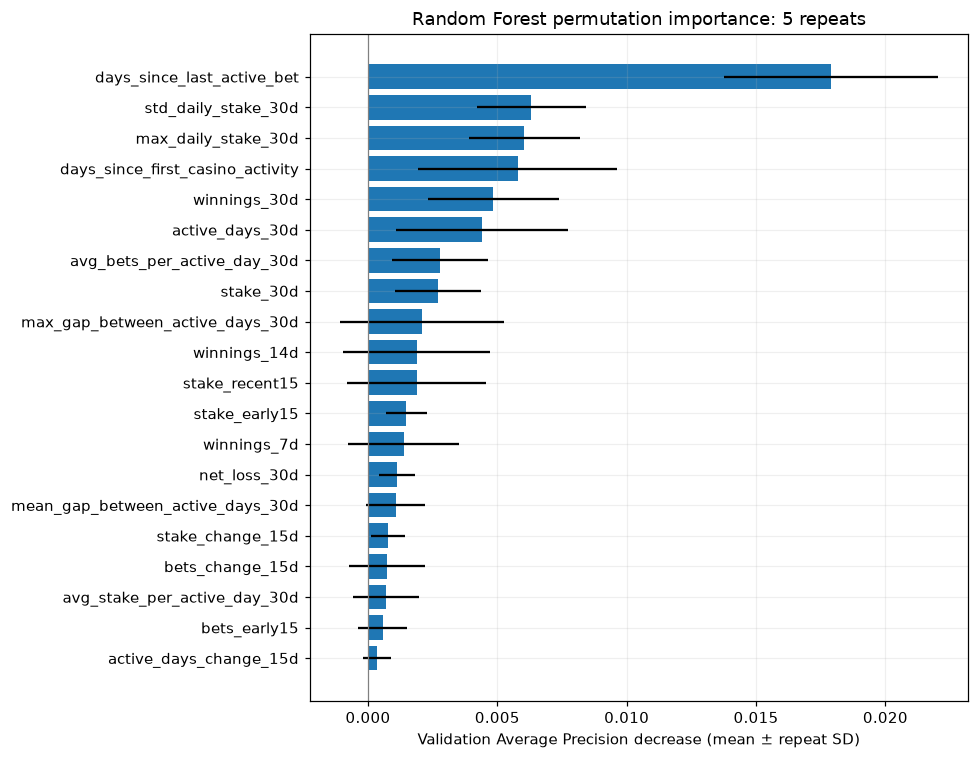

In [9]:
preprocessor = selected['preprocessing']
impurity = pd.DataFrame({'feature': preprocessor.get_feature_names_out(),
                         'importance': selected['model'].feature_importances_}).sort_values('importance', ascending=False)
assert len(impurity) == len(preprocessor.get_feature_names_out())
impurity.to_csv(REPORTS / 'random_forest_impurity_importance.csv', index=False)
display(Markdown('### Top 20 transformed features: impurity reference'))
display(impurity.head(20))
start = time.perf_counter()
permuted = permutation_importance(selected, X_validation, y_validation, scoring='average_precision',
                                 n_repeats=5, random_state=42, n_jobs=1)
permutation = pd.DataFrame({'feature': X_validation.columns, 'mean_ap_drop': permuted.importances_mean,
                           'std_ap_drop': permuted.importances_std}).sort_values('mean_ap_drop', ascending=False)
permutation.to_csv(REPORTS / 'random_forest_permutation_importance.csv', index=False)
print('Permutation seconds:', round(time.perf_counter() - start, 1))
display(Markdown('### Top 20 original predictors: validation permutation'))
display(permutation.head(20))
top = permutation.head(20).sort_values('mean_ap_drop')
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.feature, top.mean_ap_drop, xerr=top.std_ap_drop)
ax.axvline(0, color='gray', linewidth=.8)
ax.set(xlabel='Validation Average Precision decrease (mean ± repeat SD)', title='Random Forest permutation importance: 5 repeats')
save_figure(fig, 'permutation_importance')

## Validation error analysis at diagnostic threshold 0.50

Summaries describe player-snapshot groups, not individual causes of failure. TP/FP/TN/FN use observed churn and the thresholded prediction. Counts, medians and nonmissing counts are reported for a small prechosen set. Missing trend ratios retain their original meaning and are not replaced for these descriptive summaries. No player-level predictions are exported.

In [10]:
predicted_positive = probability >= .5
actual_positive = y_validation.to_numpy() == 1
outcomes = np.select([actual_positive & predicted_positive, ~actual_positive & predicted_positive,
                      ~actual_positive & ~predicted_positive, actual_positive & ~predicted_positive],
                     ['TP', 'FP', 'TN', 'FN'], default='unknown')
error_features = ['days_since_last_active_bet', 'active_days_30d', 'bets_30d', 'stake_30d',
                  'bets_change_pct_15d', 'active_days_change_15d']
descriptive = validation[error_features].assign(outcome=outcomes)
error_counts = descriptive.groupby('outcome').size().reindex(['TP', 'FP', 'TN', 'FN'], fill_value=0)
error_medians = descriptive.groupby('outcome')[error_features].median().reindex(['TP', 'FP', 'TN', 'FN'])
error_nonmissing = descriptive.groupby('outcome')[error_features].count().reindex(['TP', 'FP', 'TN', 'FN'], fill_value=0)
error_summary = error_medians.assign(observations=error_counts)
error_summary.to_csv(REPORTS / 'random_forest_error_group_medians.csv')
error_nonmissing.to_csv(REPORTS / 'random_forest_error_group_nonmissing_counts.csv')
display(error_summary)
display(error_nonmissing)
del descriptive

,days_since_last_active_bet,active_days_30d,bets_30d,stake_30d,bets_change_pct_15d,active_days_change_15d,observations
outcome,,,,,,,
TP,20.0,1.0,4.0,20.0,-100.000000,-1.0,261
FP,19.0,1.0,4.0,20.5,-100.000000,-1.0,164
TN,3.0,4.0,100.0,993.1,-52.132571,0.0,1247
FN,10.0,2.0,44.0,197.0,-100.000000,0.0,512


,days_since_last_active_bet,active_days_30d,bets_30d,stake_30d,bets_change_pct_15d,active_days_change_15d
outcome,,,,,,
TP,261,261,261,261,204,261
FP,164,164,164,164,120,164
TN,1247,1247,1247,1247,922,1247
FN,512,512,512,512,329,512


## Repeated-player dependence and next steps

The same player can occur in training and validation and at multiple snapshots. This is intentional: production repeatedly scores existing players over time. UserID is excluded from prediction, but behavioral continuity still creates dependence. Observation-level metrics and permutation variability do not account for player clustering. The primary temporal split stays unchanged.

A later sensitivity analysis can reserve a fixed UserID subset, fit on earlier snapshots from other players, and evaluate those held-out players in the same validation period. Compare its ranking/calibration with this existing-player use case; do not replace the primary evaluation or access the sealed test. Player-clustered bootstrapping could quantify uncertainty in model differences.

Before XGBoost: inspect generalization gaps, correlated features, raw calibration and drift across months. Validation has been reused for a small candidate comparison, so selection can be optimistic. Leave probability calibration and cost/capacity-based threshold choice until the final family has been selected.

In [11]:
joblib.dump(selected, MODELS / 'random_forest.joblib')
metadata = {'data_sha256': hashlib.sha256(data_path.read_bytes()).hexdigest(),
            'baseline_metrics_sha256': hashlib.sha256(baseline_path.read_bytes()).hexdigest(),
            'python': platform.python_version(), 'sklearn': sklearn.__version__,
            'numpy': np.__version__, 'pandas': pd.__version__,
            'selected_candidate': selected_name, 'parameters': selected_params,
            'permutation_scoring': 'average_precision', 'permutation_repeats': 5,
            'random_state': 42, 'test_predictions_generated': False,
            'production_threshold_selected': False, 'calibrated': False}
(REPORTS / 'random_forest_run_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
reload_model = joblib.load(MODELS / 'random_forest.joblib')
np.testing.assert_allclose(probability, guarded_probabilities(reload_model, validation, 'validation'), rtol=0, atol=1e-14)
del reload_model
summary_lines = [f"## Selected Random Forest: {selected_name}", '',
    'Configuration: ' + ', '.join(f"{k}={selected_params[k]}" for k in ['n_estimators','max_depth','min_samples_leaf','max_features','class_weight']),
    f"Train ROC-AUC {training_metrics['roc_auc']:.4f}; AP {training_metrics['average_precision']:.4f}.",
    f"Validation ROC-AUC {validation_metrics['roc_auc']:.4f}; AP {validation_metrics['average_precision']:.4f}; Brier {validation_metrics['brier_score']:.4f}.",
    f"At 0.50: precision {validation_metrics['precision']:.4f}; recall {validation_metrics['recall']:.4f}; F1 {validation_metrics['f1']:.4f}.",
    f"Top 10%: lift {validation_metrics['lift_at_top10pct']:.4f}; recall {validation_metrics['recall_at_top10pct']:.2%}.",
    f"Top 20%: lift {validation_metrics['lift_at_top20pct']:.4f}; recall {validation_metrics['recall_at_top20pct']:.2%}.",
    f"Train–validation gaps: ROC-AUC {metric_row['roc_auc_gap']:.4f}; AP {metric_row['average_precision_gap']:.4f}.",
    f"Mean raw probability {probability.mean():.2%}; observed validation churn {y_validation.mean():.2%}. "
    + ('Average risk is underpredicted.' if probability.mean() < y_validation.mean() else 'Average risk is overpredicted.'),
    'Top permutation features: ' + ', '.join(permutation.head(5).feature) + '. Recency has the largest AP drop; several smaller importances overlap within repeat variability, so their exact order is uncertain.',
    'Logistic comparison (RF minus LR): ' + '; '.join(f"{row['Metric']} {row['Difference']:+.4f}" for _, row in comparison.iterrows()) + '. Lower Brier is better; every requested comparison metric improves here.',
    f"The unrestricted initial forest scored train ROC-AUC {initial_metrics['train_roc_auc']:.4f} / AP {initial_metrics['train_average_precision']:.4f}, but validation ROC-AUC {initial_metrics['roc_auc']:.4f} / AP {initial_metrics['average_precision']:.4f}. Constraints substantially reduce this overfit, though the selected forest still has a meaningful gap.",
    f"Weighted sensitivity: AP {weighted_metrics['average_precision']:.4f}, precision {weighted_metrics['precision']:.4f}, recall {weighted_metrics['recall']:.4f}, Brier {weighted_metrics['brier_score']:.4f}. Weighting increases diagnostic recall while reducing precision and worsening Brier; primary remains unweighted.",
    f"Error analysis: TP/FP median recency is {error_medians.loc['TP', 'days_since_last_active_bet']:.0f}/{error_medians.loc['FP', 'days_since_last_active_bet']:.0f} days, and both groups have median {error_medians.loc['TP', 'active_days_30d']:.0f}/{error_medians.loc['FP', 'active_days_30d']:.0f} active days. Their similar low activity shows why threshold-positive observations are hard to separate. FN median recency is {error_medians.loc['FN', 'days_since_last_active_bet']:.0f} days versus TN {error_medians.loc['TN', 'days_since_last_active_bet']:.0f}; FN median bets are {error_medians.loc['FN', 'bets_30d']:.0f} versus TN {error_medians.loc['TN', 'bets_30d']:.0f}. These are descriptive, correlated group summaries, not causes.",
    f"Reliability: the highest-risk decile predicts {predicted_bins[-1]:.2%} against {observed_bins[-1]:.2%} observed; the lowest-risk decile predicts {predicted_bins[0]:.2%} against {observed_bins[0]:.2%}. This suggests some underconfidence (probabilities compressed toward the base rate), especially in the high-risk tail, with mixed deviations in middle bins. It does not support uniform overconfidence. RF improves Brier versus LR and its average probability is closer to prevalence; the actual results do not support assuming RF is worse calibrated. Brier also reflects discrimination, so it is not a pure calibration measure. No calibration is fitted.",
    f"Ranking material-improvement criterion met: {material}. No final winner before XGBoost.",
    'Concerns: overfitting, correlated predictors, probability calibration, validation selection optimism and repeated-player dependence.',
    'Model saved locally; tracked outputs are aggregate only. Test remains sealed. No production threshold or calibration selected.']
summary_text = '\n\n'.join(summary_lines)
display(Markdown(summary_text))
(REPORTS / 'random_forest_summary.md').write_text(summary_text, encoding='utf-8')

## Selected Random Forest: depth8_leaf20_half



Configuration: n_estimators=500, max_depth=8, min_samples_leaf=20, max_features=0.5, class_weight=None

Train ROC-AUC 0.8178; AP 0.6859.

Validation ROC-AUC 0.7415; AP 0.5594; Brier 0.1911.

At 0.50: precision 0.6141; recall 0.3376; F1 0.4357.

Top 10%: lift 1.7675; recall 17.72%.

Top 20%: lift 1.7198; recall 34.41%.

Train–validation gaps: ROC-AUC 0.0763; AP 0.1265.

Mean raw probability 34.48%; observed validation churn 35.39%. Average risk is underpredicted.

Top permutation features: days_since_last_active_bet, std_daily_stake_30d, max_daily_stake_30d, days_since_first_casino_activity, winnings_30d. Recency has the largest AP drop; several smaller importances overlap within repeat variability, so their exact order is uncertain.

Logistic comparison (RF minus LR): roc_auc +0.0119; average_precision +0.0252; brier_score -0.0052; precision +0.0667; recall +0.0763; f1 +0.0820; lift_at_top10pct +0.1806; recall_at_top10pct +0.0181; lift_at_top20pct +0.1422; recall_at_top20pct +0.0285. Lower Brier is better; every requested comparison metric improves here.

The unrestricted initial forest scored train ROC-AUC 1.0000 / AP 1.0000, but validation ROC-AUC 0.7128 / AP 0.5154. Constraints substantially reduce this overfit, though the selected forest still has a meaningful gap.

Weighted sensitivity: AP 0.5559, precision 0.5057, recall 0.7503, Brier 0.1973. Weighting increases diagnostic recall while reducing precision and worsening Brier; primary remains unweighted.

Error analysis: TP/FP median recency is 20/19 days, and both groups have median 1/1 active days. Their similar low activity shows why threshold-positive observations are hard to separate. FN median recency is 10 days versus TN 3; FN median bets are 44 versus TN 100. These are descriptive, correlated group summaries, not causes.

Reliability: the highest-risk decile predicts 57.82% against 62.56% observed; the lowest-risk decile predicts 4.48% against 1.37%. This suggests some underconfidence (probabilities compressed toward the base rate), especially in the high-risk tail, with mixed deviations in middle bins. It does not support uniform overconfidence. RF improves Brier versus LR and its average probability is closer to prevalence; the actual results do not support assuming RF is worse calibrated. Brier also reflects discrimination, so it is not a pure calibration measure. No calibration is fitted.

Ranking material-improvement criterion met: True. No final winner before XGBoost.

Concerns: overfitting, correlated predictors, probability calibration, validation selection optimism and repeated-player dependence.

Model saved locally; tracked outputs are aggregate only. Test remains sealed. No production threshold or calibration selected.

2790